In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [51]:
loan=pd.read_csv('/content/loan_dataset.csv')
loan.head()

,loan_id,source,financial_institution,interest_rate,unpaid_principal_bal,loan_term,origination_date,first_payment_date,loan_to_value,number_of_borrowers,...,m4,m5,m6,m7,m8,m9,m10,m11,m12,m13
0,268055008619,Z,"Turner, Baldwin and Rhodes",4.250,214000,360,2012-03-01,05/2012,95,1.0,...,0,0,0,1,0,0,0,0,0,1
1,672831657627,Y,"Swanson, Newton and Miller",4.875,144000,360,2012-01-01,03/2012,72,1.0,...,0,0,0,0,0,0,0,1,0,1
2,742515242108,Z,Thornton-Davis,3.250,366000,180,2012-01-01,03/2012,49,1.0,...,0,0,0,0,0,0,0,0,0,1
3,601385667462,X,OTHER,4.750,135000,360,2012-02-01,04/2012,46,2.0,...,0,0,0,0,0,1,1,1,1,1
4,273870029961,X,OTHER,4.750,124000,360,2012-02-01,04/2012,80,1.0,...,3,4,5,6,7,8,9,10,11,1


In [52]:
loan.shape

(116058, 29)

In [53]:
loan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 116058 entries, 0 to 116057
Data columns (total 29 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   loan_id                   116058 non-null  int64  
 1   source                    116058 non-null  object 
 2   financial_institution     116058 non-null  object 
 3   interest_rate             116058 non-null  float64
 4   unpaid_principal_bal      116058 non-null  int64  
 5   loan_term                 116058 non-null  int64  
 6   origination_date          116058 non-null  object 
 7   first_payment_date        116058 non-null  object 
 8   loan_to_value             116058 non-null  int64  
 9   number_of_borrowers       116058 non-null  float64
 10  debt_to_income_ratio      116058 non-null  float64
 11  borrower_credit_score     116058 non-null  float64
 12  loan_purpose              116058 non-null  object 
 13  insurance_percent         116058 non-null  f

In [54]:
loan['origination_date'] = pd.to_datetime(loan['origination_date'])

In [55]:
loan['first_payment_date'] = pd.to_datetime(loan['first_payment_date'])

/tmp/ipykernel_1544/3364656723.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  loan['first_payment_date'] = pd.to_datetime(loan['first_payment_date'])


In [56]:
loan['origination_year'] = loan['origination_date'].dt.year
loan['origination_month'] = loan['origination_date'].dt.month
loan['origination_day'] = loan['origination_date'].dt.day

In [57]:
loan.drop('origination_date', axis=1, inplace=True)

In [58]:
loan['payment_year'] = loan['first_payment_date'].dt.year
loan['payment_month'] = loan['first_payment_date'].dt.month
loan['payment_day'] = loan['first_payment_date'].dt.day

In [59]:
loan.drop('first_payment_date', axis=1, inplace=True)

In [60]:
loan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 116058 entries, 0 to 116057
Data columns (total 33 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   loan_id                   116058 non-null  int64  
 1   source                    116058 non-null  object 
 2   financial_institution     116058 non-null  object 
 3   interest_rate             116058 non-null  float64
 4   unpaid_principal_bal      116058 non-null  int64  
 5   loan_term                 116058 non-null  int64  
 6   loan_to_value             116058 non-null  int64  
 7   number_of_borrowers       116058 non-null  float64
 8   debt_to_income_ratio      116058 non-null  float64
 9   borrower_credit_score     116058 non-null  float64
 10  loan_purpose              116058 non-null  object 
 11  insurance_percent         116058 non-null  float64
 12  co-borrower_credit_score  116058 non-null  float64
 13  insurance_type            116058 non-null  f

In [61]:
loan.describe()

,loan_id,interest_rate,unpaid_principal_bal,loan_term,loan_to_value,number_of_borrowers,debt_to_income_ratio,borrower_credit_score,insurance_percent,co-borrower_credit_score,...,m10,m11,m12,m13,origination_year,origination_month,origination_day,payment_year,payment_month,payment_day
count,1.160580e+05,116058.000000,1.160580e+05,116058.000000,116058.000000,116058.000000,116058.000000,116058.000000,116058.000000,116058.000000,...,116058.000000,116058.000000,116058.000000,116058.000000,116058.0,116058.000000,116058.0,116058.0,116058.000000,116058.0
mean,5.494155e+11,3.868961,2.082262e+05,292.280997,67.431939,1.593186,30.742293,769.926778,2.786288,459.611565,...,0.006617,0.007109,0.008065,0.005480,2012.0,1.703062,1.0,2012.0,3.709507,1.0
std,2.597560e+11,0.461020,1.146851e+05,89.762415,17.291719,0.491242,9.730798,42.210706,8.096464,381.946926,...,0.148430,0.162884,0.178128,0.073824,0.0,0.678898,0.0,0.0,0.688385,0.0
min,1.000009e+11,2.250000,1.100000e+04,60.000000,6.000000,1.000000,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,2012.0,1.000000,1.0,2012.0,2.000000,1.0
25%,3.244656e+11,3.500000,1.200000e+05,180.000000,57.000000,1.000000,23.000000,751.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,2012.0,1.000000,1.0,2012.0,3.000000,1.0
50%,5.486239e+11,3.875000,1.830000e+05,360.000000,72.000000,2.000000,31.000000,782.000000,0.000000,740.000000,...,0.000000,0.000000,0.000000,0.000000,2012.0,2.000000,1.0,2012.0,4.000000,1.0
75%,7.743034e+11,4.125000,2.780000e+05,360.000000,80.000000,2.000000,39.000000,800.000000,0.000000,791.000000,...,0.000000,0.000000,0.000000,0.000000,2012.0,2.000000,1.0,2012.0,4.000000,1.0
max,9.999971e+11,6.750000,1.200000e+06,360.000000,97.000000,2.000000,64.000000,840.000000,40.000000,836.000000,...,12.000000,13.000000,14.000000,1.000000,2012.0,3.000000,1.0,2012.0,5.000000,1.0


In [62]:
loan.select_dtypes(include='object').columns

Index(['source', 'financial_institution', 'loan_purpose'], dtype='object')

In [63]:
loan.isna().sum()

,0
loan_id,0
source,0
financial_institution,0
interest_rate,0
unpaid_principal_bal,0
loan_term,0
loan_to_value,0
number_of_borrowers,0
debt_to_income_ratio,0
borrower_credit_score,0


In [64]:
loan['co-borrower_credit_score'].unique()

array([  0., 638., 700., 770., 813., 658., 742., 736., 729., 625., 753.,
       759., 722., 680., 732., 780., 787., 766., 702., 785., 788., 697.,
       731., 685., 738., 699., 760., 668., 656., 671., 726., 781., 660.,
       718., 693., 808., 666., 648., 696., 804., 703., 704., 694., 777.,
       728., 687., 674., 644., 801., 727., 786., 657., 756., 774., 768.,
       795., 775., 715., 716., 810., 761., 806., 749., 802., 637., 772.,
       765., 667., 767., 714., 633., 698., 776., 798., 707., 659., 744.,
       683., 800., 809., 675., 670., 792., 673., 720., 711., 807., 689.,
       750., 754., 725., 789., 799., 663., 752., 672., 745., 665., 763.,
       684., 796., 635., 793., 782., 695., 764., 647., 721., 712., 740.,
       779., 664., 723., 628., 812., 790., 762., 719., 817., 640., 805.,
       677., 690., 771., 661., 713., 686., 730., 645., 755., 773., 784.,
       797., 803., 739., 814., 819., 791., 815., 794., 751., 778., 820.,
       816., 758., 811., 743., 821., 757., 783., 74

In [65]:
loan['co-borrower_credit_score'] = loan['co-borrower_credit_score'].replace(0, np.nan)

In [66]:
loan['co-borrower_credit_score'].isna().sum()

np.int64(47263)

In [67]:
loan = loan.drop('co-borrower_credit_score', axis=1)

In [68]:
loan['borrower_credit_score'].unique()

array([694., 697., 780., 633., 681., 675., 723., 652., 808., 702., 738.,
       742., 739., 757., 687., 731., 699., 669., 711., 640., 621., 746.,
       667., 779., 807., 683., 776., 747., 630., 661., 759., 650., 686.,
       741., 802., 726., 801., 627., 648., 641., 692., 678., 789., 758.,
       679., 740., 729., 733., 626., 790., 778., 787., 714., 783., 795.,
       672., 771., 764., 784., 685., 684., 654., 775., 727., 712., 761.,
       691., 701., 773., 716., 777., 753., 689., 696., 709., 760., 668.,
       635., 703., 677., 743., 786., 768., 665., 639., 717., 637., 809.,
       674., 676., 756., 737., 806., 700., 763., 659., 707., 730., 719.,
       798., 673., 643., 645., 666., 663., 657., 658., 660., 744., 680.,
       811., 813., 804., 734., 728., 705., 770., 749., 794., 793., 785.,
       664., 754., 721., 646., 755., 688., 655., 769., 799., 810., 708.,
       821., 796., 670., 788., 745., 629., 698., 765., 624., 682., 695.,
       750., 735., 706., 690., 767., 766., 815., 77

In [69]:
loan['borrower_credit_score'] = loan['borrower_credit_score'].replace(0, np.nan)

In [70]:
loan['borrower_credit_score'].isna().sum()

np.int64(51)

In [71]:
loan['borrower_credit_score'] = loan['borrower_credit_score'].fillna(
    loan['borrower_credit_score'].median())

In [72]:
loan['borrower_credit_score'].isna().sum()

np.int64(0)

In [73]:
loan['loan_id'].nunique()

116058

In [74]:
loan=loan.drop('loan_id',axis=1)

In [75]:
loan.head()

,source,financial_institution,interest_rate,unpaid_principal_bal,loan_term,loan_to_value,number_of_borrowers,debt_to_income_ratio,borrower_credit_score,loan_purpose,...,m10,m11,m12,m13,origination_year,origination_month,origination_day,payment_year,payment_month,payment_day
0,Z,"Turner, Baldwin and Rhodes",4.250,214000,360,95,1.0,22.0,694.0,C86,...,0,0,0,1,2012,3,1,2012,5,1
1,Y,"Swanson, Newton and Miller",4.875,144000,360,72,1.0,44.0,697.0,B12,...,0,1,0,1,2012,1,1,2012,3,1
2,Z,Thornton-Davis,3.250,366000,180,49,1.0,33.0,780.0,B12,...,0,0,0,1,2012,1,1,2012,3,1
3,X,OTHER,4.750,135000,360,46,2.0,44.0,633.0,B12,...,1,1,1,1,2012,2,1,2012,4,1
4,X,OTHER,4.750,124000,360,80,1.0,43.0,681.0,C86,...,9,10,11,1,2012,2,1,2012,4,1


#outlier handling

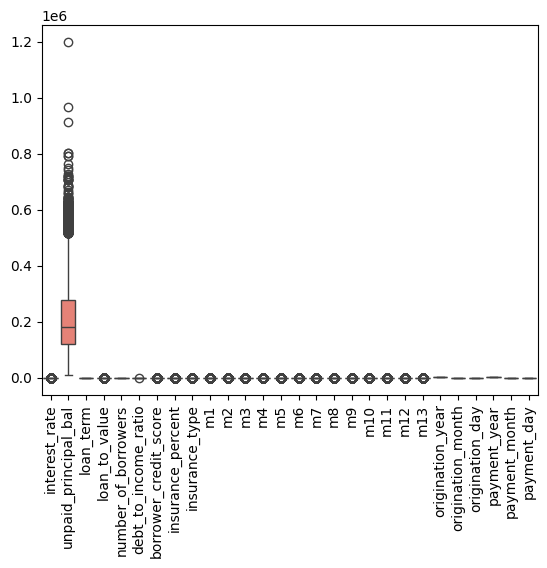

In [76]:
sns.boxplot(loan)
plt.xticks(rotation=90)
plt.show()

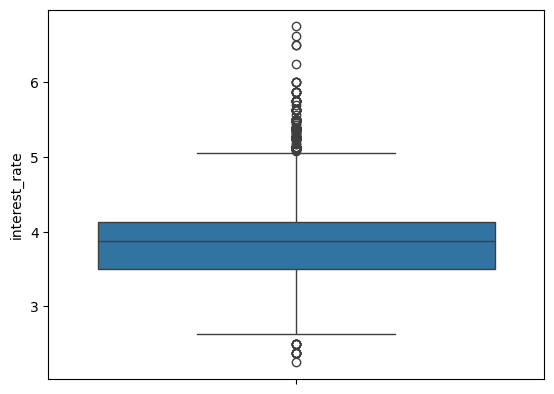

In [77]:
sns.boxplot(loan['interest_rate'])
plt.show()

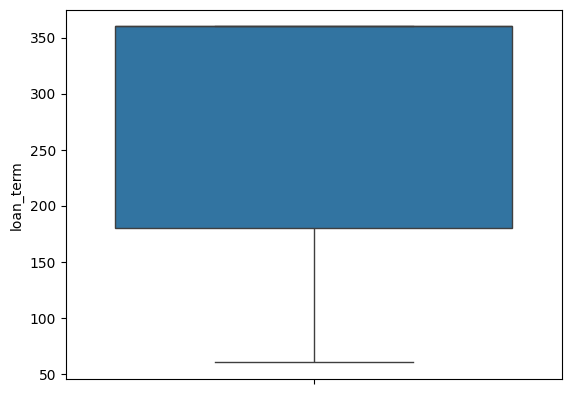

In [78]:
sns.boxplot(loan['loan_term'])
plt.show()


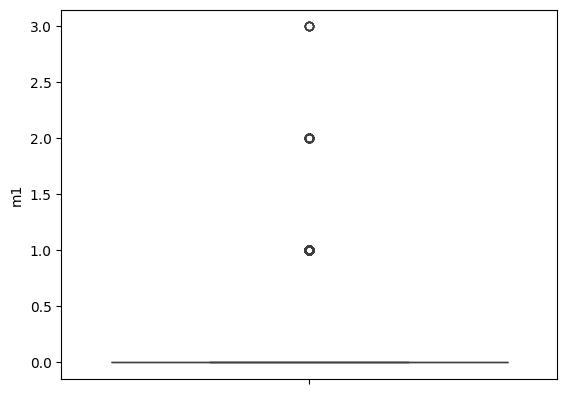

In [79]:
sns.boxplot(loan['m1'])
plt.show()

In [80]:
q1 = loan['interest_rate'].quantile(0.25)
q3 = loan['interest_rate'].quantile(0.75)

print(f'Q1 = {q1}\nQ3 = {q3}')

iqr = q3 - q1

up_lim_interest_rate = q3 + (1.5 * iqr)
low_lim_interest_rate = q1 - (1.5 * iqr)

print(f'IQR = {iqr}\nUp_lim = {up_lim_interest_rate}\nLow_lim = {low_lim_interest_rate}')

Q1 = 3.5
Q3 = 4.125
IQR = 0.625
Up_lim = 5.0625
Low_lim = 2.5625


In [81]:
outliers_interest_rate = loan[(loan['interest_rate'] > up_lim_interest_rate) | (loan['interest_rate'] < low_lim_interest_rate)]
outliers_interest_rate

,source,financial_institution,interest_rate,unpaid_principal_bal,loan_term,loan_to_value,number_of_borrowers,debt_to_income_ratio,borrower_credit_score,loan_purpose,...,m10,m11,m12,m13,origination_year,origination_month,origination_day,payment_year,payment_month,payment_day
14,Y,Edwards-Hoffman,5.125,84000,360,80,1.0,46.0,757.0,C86,...,0,0,0,1,2012,2,1,2012,4,1
39,X,"Swanson, Newton and Miller",5.500,42000,360,79,1.0,33.0,686.0,B12,...,2,2,1,1,2012,1,1,2012,3,1
61,X,"Miller, Mcclure and Allen",5.125,98000,360,35,1.0,45.0,626.0,B12,...,0,0,1,1,2012,3,1,2012,5,1
73,X,OTHER,5.250,64000,360,73,1.0,49.0,685.0,A23,...,1,2,3,1,2012,1,1,2012,3,1
88,Y,Browning-Hart,5.125,207000,360,75,1.0,18.0,701.0,C86,...,4,5,6,1,2012,1,1,2012,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115082,X,OTHER,5.250,52000,360,80,1.0,36.0,641.0,C86,...,0,0,0,0,2012,2,1,2012,4,1
115236,X,"Swanson, Newton and Miller",5.125,50000,360,64,1.0,33.0,665.0,B12,...,0,0,0,0,2012,1,1,2012,3,1
115487,Y,Edwards-Hoffman,5.500,264000,360,80,2.0,33.0,659.0,C86,...,0,0,0,0,2012,2,1,2012,4,1
115777,Y,Browning-Hart,5.250,74000,360,80,2.0,26.0,788.0,C86,...,0,0,0,0,2012,2,1,2012,4,1


In [82]:
loan.loc[loan['interest_rate'] > up_lim_interest_rate,'interest_rate'] = up_lim_interest_rate
loan.loc[loan['interest_rate'] < low_lim_interest_rate,'interest_rate'] = low_lim_interest_rate

In [83]:
loan['interest_rate'].unique()

array([4.25  , 4.875 , 3.25  , 4.75  , 4.375 , 4.    , 4.5   , 4.125 ,
       3.75  , 4.625 , 5.0625, 3.375 , 3.99  , 4.312 , 3.875 , 3.5   ,
       3.33  , 5.    , 3.625 , 2.875 , 3.46  , 3.98  , 3.928 , 3.95  ,
       4.05  , 3.125 , 3.    , 3.74  , 3.709 , 4.3   , 4.99  , 4.225 ,
       4.28  , 4.58  , 4.9   , 4.49  , 4.1   , 3.856 , 4.54  , 3.77  ,
       3.504 , 3.958 , 4.06  , 3.87  , 3.1   , 3.94  , 4.124 , 4.015 ,
       2.95  , 3.167 , 3.835 , 3.938 , 3.503 , 3.438 , 3.49  , 3.24  ,
       4.19  , 3.902 , 4.46  , 3.289 , 3.978 , 4.03  , 4.358 , 2.99  ,
       3.795 , 3.074 , 3.91  , 2.975 , 3.71  , 2.75  , 4.08  , 4.876 ,
       3.185 , 3.35  , 4.2   , 4.864 , 3.613 , 3.865 , 4.917 , 3.908 ,
       3.337 , 3.92  , 2.625 , 3.43  , 3.65  , 4.17  , 3.85  , 3.985 ,
       2.775 , 3.79  , 3.67  , 3.947 , 4.048 , 2.8   , 3.17  , 4.21  ,
       4.849 , 3.83  , 4.521 , 3.852 , 3.943 , 3.999 , 3.972 , 3.18  ,
       3.476 , 4.986 , 3.42  , 3.2   , 4.119 , 3.175 , 3.41  , 3.145 ,
      

In [84]:
#outlier count
numeric_cols = loan.select_dtypes(include=['int64', 'float64']).columns

# Remove target column
numeric_cols = numeric_cols.drop('m13')

for col in numeric_cols:
    Q1 = loan[col].quantile(0.25)
    Q3 = loan[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = ((loan[col] < lower_limit) | (loan[col] > upper_limit)).sum()

    print(f"{col}: {outlier_count} outliers")

interest_rate: 0 outliers
unpaid_principal_bal: 1742 outliers
loan_term: 0 outliers
loan_to_value: 1486 outliers
number_of_borrowers: 0 outliers
debt_to_income_ratio: 1 outliers
borrower_credit_score: 3678 outliers
insurance_percent: 13603 outliers
insurance_type: 378 outliers
m1: 329 outliers
m2: 214 outliers
m3: 190 outliers
m4: 198 outliers
m5: 306 outliers
m6: 273 outliers
m7: 330 outliers
m8: 362 outliers
m9: 371 outliers
m10: 445 outliers
m11: 446 outliers
m12: 501 outliers


In [85]:
cols = [
    'unpaid_principal_bal',
    'loan_to_value',
    'borrower_credit_score',
    'insurance_percent'
]

for col in cols:
    print("\n", col)
    print("Min:", loan[col].min())
    print("Max:", loan[col].max())
    print("Q1:", loan[col].quantile(0.25))
    print("Q3:", loan[col].quantile(0.75))


 unpaid_principal_bal
Min: 11000
Max: 1200000
Q1: 120000.0
Q3: 278000.0

 loan_to_value
Min: 6
Max: 97
Q1: 57.0
Q3: 80.0

 borrower_credit_score
Min: 480.0
Max: 840.0
Q1: 751.0
Q3: 800.0

 insurance_percent
Min: 0.0
Max: 40.0
Q1: 0.0
Q3: 0.0


In [86]:
(loan['borrower_credit_score'] == 0).sum()

np.int64(0)

In [87]:
loan['borrower_credit_score'].value_counts().head(10)

,count
borrower_credit_score,
801.0,2271
809.0,2246
802.0,2067
808.0,2024
791.0,1958
800.0,1862
798.0,1846
797.0,1818
804.0,1807


#encoding

In [88]:
loan.select_dtypes(include='object').columns

Index(['source', 'financial_institution', 'loan_purpose'], dtype='object')

In [89]:
for col in loan.select_dtypes(include='object').columns:
    print("\n", col)
    print(loan[col].unique()[:10])


 source
['Z' 'Y' 'X']

 financial_institution
['Turner, Baldwin and Rhodes' 'Swanson, Newton and Miller'
 'Thornton-Davis' 'OTHER' 'Browning-Hart' 'Richardson Ltd'
 'Edwards-Hoffman' 'Richards-Walters' 'Martinez, Duffy and Bird'
 'Miller, Mcclure and Allen']

 loan_purpose
['C86' 'B12' 'A23']


In [90]:
cate_cols = loan.select_dtypes(include=['object']).columns
print(cate_cols)

Index(['source', 'financial_institution', 'loan_purpose'], dtype='object')


In [91]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoded_data = encoder.fit_transform(loan[cate_cols])

In [92]:
encoded_data.shape

(116058, 25)

In [93]:
#to confirm encoding
print("Original categorical columns:")
print(loan[cate_cols].head())

print("\nEncoded column names:")
print(encoder.get_feature_names_out(cate_cols))

Original categorical columns:
  source       financial_institution loan_purpose
0      Z  Turner, Baldwin and Rhodes          C86
1      Y  Swanson, Newton and Miller          B12
2      Z              Thornton-Davis          B12
3      X                       OTHER          B12
4      X                       OTHER          C86

Encoded column names:
['source_X' 'source_Y' 'source_Z' 'financial_institution_Anderson-Taylor'
 'financial_institution_Browning-Hart'
 'financial_institution_Chapman-Mcmahon'
 'financial_institution_Cole, Brooks and Vincent'
 'financial_institution_Edwards-Hoffman'
 'financial_institution_Martinez, Duffy and Bird'
 'financial_institution_Miller, Mcclure and Allen'
 'financial_institution_Nicholson Group' 'financial_institution_OTHER'
 'financial_institution_Richards-Walters'
 'financial_institution_Richardson Ltd'
 'financial_institution_Romero, Woods and Johnson'
 'financial_institution_Sanchez, Hays and Wilkerson'
 'financial_institution_Sanchez-Robinson'
 '

In [94]:
#target feature splitting
X = loan.drop('m13', axis=1)
y = loan['m13']

In [95]:
print(X.shape)
print(y.shape)

(116058, 30)
(116058,)


In [96]:
print(encoded_data.dtype)

float64


In [97]:
# Drop the row where target 'm13' has NaN
loan = loan.dropna(subset=['m13'])
X = loan.drop('m13', axis=1)
y = loan['m13']

In [99]:
# This tells us how many 0s and 1s are in m13.
print(y.value_counts())
print(y.value_counts(normalize=True))

m13
0    115422
1       636
Name: count, dtype: int64
m13
0    0.99452
1    0.00548
Name: proportion, dtype: float64


#scaling

In [100]:
loan.select_dtypes(include=['float','int']).columns

Index(['interest_rate', 'unpaid_principal_bal', 'loan_term', 'loan_to_value',
       'number_of_borrowers', 'debt_to_income_ratio', 'borrower_credit_score',
       'insurance_percent', 'insurance_type', 'm1', 'm2', 'm3', 'm4', 'm5',
       'm6', 'm7', 'm8', 'm9', 'm10', 'm11', 'm12', 'm13', 'origination_year',
       'origination_month', 'origination_day', 'payment_year', 'payment_month',
       'payment_day'],
      dtype='object')

In [101]:
scale_cols = ['interest_rate',
    'unpaid_principal_bal',
    'loan_term',
    'loan_to_value',
    'number_of_borrowers',
    'debt_to_income_ratio',
    'borrower_credit_score',
    'insurance_percent','insurance_type']

In [102]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
loan[scale_cols] = scaler.fit_transform(loan[scale_cols])

In [104]:
from sklearn.metrics import confusion_matrix,precision_score
from sklearn.metrics import accuracy_score,f1_score
from sklearn.metrics import recall_score

In [106]:
# Drop categorical and datetime columns
features_numeric = loan.drop(columns=['source', 'financial_institution', 'loan_purpose', 'origination_date', 'first_payment_date', 'm13'], errors='ignore')

# Recreate encoded DataFrame using the encoded numpy array and encoder names
encoded_loan = pd.DataFrame(encoded_data, columns=encoder.get_feature_names_out(cate_cols), index=loan.index)

# Ensure encoded_loan matches the indices of the filtered loan DataFrame
encoded_loan_aligned = encoded_loan.loc[loan.index]

# Concatenate aligned one-hot encoded columns
X_final = pd.concat([features_numeric, encoded_loan_aligned], axis=1)
y_final = loan['m13']

# Re-split the dataset with completely numeric features
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    X_final, y_final, test_size=0.2, random_state=42, stratify=y_final
)

#logistic regression

In [107]:
#logistics regression model
from sklearn.linear_model import LogisticRegression

In [109]:
lr_model = LogisticRegression(max_iter=10000)
lr_model.fit(x_train, y_train)
y_pred_lr_model = lr_model.predict(x_test)

In [110]:
print(confusion_matrix(y_test, y_pred_lr_model))
print('Accuracy is:',accuracy_score(y_test,y_pred_lr_model))
print('Precision is:',precision_score(y_test,y_pred_lr_model))
print('Recall is:',recall_score(y_test,y_pred_lr_model))
print('F1 score is',f1_score(y_test,y_pred_lr_model))

[[23075    10]
 [   86    41]]
Accuracy is: 0.9958642081681889
Precision is: 0.803921568627451
Recall is: 0.3228346456692913
F1 score is 0.4606741573033708


#SVM

In [114]:
from sklearn.svm import SVC


In [115]:
#linear kernel
svm_linear = SVC(kernel='linear')    #kernel='linear' is a hyperparameter
svm_linear.fit(x_train,y_train)
y_pred_svm_linear = svm_linear.predict(x_test)
print(confusion_matrix(y_test,y_pred_svm_linear))
print(accuracy_score(y_test,y_pred_svm_linear))
print(precision_score(y_test,y_pred_svm_linear))
print(recall_score(y_test,y_pred_svm_linear))
print(f1_score(y_test,y_pred_svm_linear))
print(f1_score(y_test,y_pred_svm_linear))

[[23075    10]
 [   87    40]]
0.9958211270032742
0.8
0.31496062992125984
0.4519774011299435
0.4519774011299435


In [116]:
#polynomial kernel
svm_poly = SVC(kernel='poly')
svm_poly.fit(x_train,y_train)
y_pred_svm_poly = svm_poly.predict(x_test)
print(confusion_matrix(y_test,y_pred_svm_poly))
print(accuracy_score(y_test,y_pred_svm_poly))
print(precision_score(y_test,y_pred_svm_poly))
print(recall_score(y_test,y_pred_svm_poly))
print(f1_score(y_test,y_pred_svm_poly))

[[23085     0]
 [  127     0]]
0.9945286920558332
0.0
0.0
0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [117]:
#rbf kernel
svm_rbf = SVC(kernel='rbf')
svm_rbf.fit(x_train,y_train)
y_pred_svm_rbf = svm_rbf.predict(x_test)
print(confusion_matrix(y_test,y_pred_svm_rbf))
print(accuracy_score(y_test,y_pred_svm_rbf))
print(precision_score(y_test,y_pred_svm_rbf))
print(recall_score(y_test,y_pred_svm_rbf))
print(f1_score(y_test,y_pred_svm_rbf))

[[23085     0]
 [  127     0]]
0.9945286920558332
0.0
0.0
0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


#decision tree

In [ ]:
#decision Trees
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(criterion='entropy',random_state=42)   #kernel='linear' is a hyperparameter
dt.fit(x_train,y_train)
y_pred_dt = dt.predict(x_test)
print(confusion_matrix(y_test,y_pred_dt))
print(accuracy_score(y_test,y_pred_dt))
print(accuracy_score(y_test,y_pred_dt))
print(precision_score(y_test,y_pred_dt))
print(recall_score(y_test,y_pred_dt))
print(f1_score(y_test,y_pred_dt))

In [119]:
# Random Forest Training
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(criterion='entropy', random_state=42)
rf.fit(x_train, y_train)
y_pred_rf = rf.predict(x_test)

# Print metrics
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
print(confusion_matrix(y_test, y_pred_rf))
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

[[23076     9]
 [   85    42]]
Accuracy: 0.9959503704980183
Precision: 0.8235294117647058
Recall: 0.33070866141732286
F1 Score: 0.47191011235955055


In [120]:
#Adaboost (Adaptive learning)
from sklearn.ensemble import AdaBoostClassifier

In [121]:
adaboost_clf = AdaBoostClassifier(random_state=42)
adaboost_clf.fit(x_train, y_train)
y_pred_adaboost = adaboost_clf.predict(x_test)
print(confusion_matrix(y_test, y_pred_adaboost))
print('Accuracy', accuracy_score(y_test, y_pred_adaboost))
print('Precision', precision_score(y_test, y_pred_adaboost))
print('recall_score', recall_score(y_test, y_pred_adaboost))
print('f1_score', f1_score(y_test, y_pred_adaboost))

[[23062    23]
 [   80    47]]
Accuracy 0.995562640013786
Precision 0.6714285714285714
recall_score 0.3700787401574803
f1_score 0.47715736040609136


In [122]:
#gradient boost
from sklearn.ensemble import GradientBoostingClassifier

In [123]:
gradboost_clf = GradientBoostingClassifier(random_state=42)
gradboost_clf.fit(x_train, y_train)
y_pred_gradboost = gradboost_clf.predict(x_test)
print('Accuracy = ', accuracy_score(y_test, y_pred_gradboost))
print('Precision = ', precision_score(y_test, y_pred_gradboost))
print('recall = ', recall_score(y_test, y_pred_gradboost))
print('f1 score = ', f1_score(y_test, y_pred_gradboost))
print(confusion_matrix(y_test, y_pred_gradboost))

Accuracy =  0.9946148543856626
Precision =  0.5384615384615384
recall =  0.11023622047244094
f1 score =  0.1830065359477124
[[23073    12]
 [  113    14]]


In [ ]:
# XGBoost (Extreme Gradient Boosting)

In [125]:
import xgboost as xgb

xgboost_clf = xgb.XGBClassifier(random_state=42)
xgboost_clf.fit(x_train, y_train)
y_pred_xgboost = xgboost_clf.predict(x_test)
print('Accuracy = ', accuracy_score(y_test, y_pred_xgboost))
print('Precision = ', precision_score(y_test, y_pred_xgboost))
print('recall = ', recall_score(y_test, y_pred_xgboost))
print('f1 score = ', f1_score(y_test, y_pred_xgboost))
print(confusion_matrix(y_test, y_pred_xgboost))

Accuracy =  0.9952179906944684
Precision =  0.5975609756097561
recall =  0.3858267716535433
f1 score =  0.4688995215311005
[[23052    33]
 [   78    49]]


**XGBoost** as the best overall model.

Accuracy: 99.5%
Precision: 59.7%
Recall: 38.5%
F1-score: 46.8%

XGBoost has the **highest F1-score** and **highest recall** among your tested models.

Although Logistic Regression achieved slightly higher accuracy, XGBoost provided better recall and F1-score, making it more suitable for identifying positive cases in this imbalanced classification problem